# Week 5: Plotting and image display

**GEOG0111 Scientific Computing**
MSc Environmental Modelling · MSc Remote Sensing and Environmental Mapping · UCL Geography

A good figure is often the main result of an analysis. In Part B, **20%** of the mark is for interpretation, which is built on your figures, and the data processing section asks you to show and explore your data. This week:

1. the anatomy of a `matplotlib` figure: `fig`, `ax`, labels, legends and units;
2. line plots, several panels, scatter plots, bar charts, histograms and error bars, using the **Heathrow** and **ONI** data from Week 4;
3. time axes, moving averages and highlighting periods;
4. **saving** figures for reports;
5. **images as arrays**: displaying a real satellite image and single bands, colourmaps, contrast stretching and colourbars;
6. **categorical** rasters (land-cover-style maps) with proper legends.

> **Student version.** It contains exercises but no answers. Try each exercise yourself before asking for help or using AI.

## Learning outcomes

By the end of this notebook you should be able to:

- create figures with `fig, ax = plt.subplots()` and give them titles, axis labels **with units**, and legends;
- choose a suitable plot type: line, scatter, bar, histogram, error bars or shaded range;
- lay out several panels with `subplots`, and loop over them;
- plot time series with real dates, moving averages and highlighted periods;
- save publication-quality figures with `savefig`;
- display RGB images and single bands with `imshow`, with a suitable colourmap, stretch and colourbar;
- display categorical rasters with a discrete colourmap and a legend;
- write reusable plotting **functions** (Part B style).

### How to use this notebook

- Run the cells **in order**. Section 0 rebuilds the data from Week 4.
- The module's AI rules apply. Plotting code has many small options, which makes AI useful for *"how do I move the legend outside the plot?"*. But **check every figure yourself**: plausible-looking plots can still be wrong or misleading.
- **Working locally in VS Code?** Everything works without changes (no shell commands). You need `matplotlib`, `pandas`, `requests` and `pillow`.

> **Part B figure rules** (from the suggested-topic templates): use clear **static** figures (no interactive maps). Each map or plot needs a **title**, **axis labels** where relevant, a **colourbar with units**, and a clear **legend or explanation** in the surrounding text.

---
# 0. Setup: imports and the Week 4 data

The cell below saves the Week 4 functions `download_file()` and `read_met_station()` in a small **module**, `climate_utils.py` (Week 3, section 4), so we can import them. Then we download, or rebuild from the offline excerpt, the Heathrow and ONI data.

In [1]:
%%writefile climate_utils.py
"""Helper functions from Week 4: download and read Met Office station data."""
from pathlib import Path
import pandas as pd
import requests


def download_file(url, out_path, overwrite=False, timeout=60):
    """Download url to out_path (unless it already exists) and return the Path."""
    out_path = Path(out_path)
    if out_path.exists() and out_path.stat().st_size > 0 and not overwrite:
        return out_path
    out_path.parent.mkdir(parents=True, exist_ok=True)
    r = requests.get(url, timeout=timeout)
    r.raise_for_status()
    out_path.write_bytes(r.content)
    return out_path


def find_data_start(lines):
    """Return the index of the first line that starts with a 4-digit year."""
    for i, line in enumerate(lines):
        parts = line.split()
        if len(parts) > 1 and len(parts[0]) == 4 and parts[0].isdigit():
            return i
    raise ValueError('no data line found')


def read_met_station(path):
    """Read a Met Office historic station data file into a clean DataFrame."""
    path = Path(path)
    start = find_data_start(path.read_text().splitlines())
    names = ['year', 'month', 'tmax', 'tmin', 'af', 'rain', 'sun', 'status']
    df = pd.read_csv(path, sep=r'\s+', skiprows=start, header=None,
                     names=names, dtype=str, engine='python')
    for col in ['tmax', 'tmin', 'af', 'rain', 'sun']:
        df[col] = pd.to_numeric(df[col].str.replace(r'[*#]', '', regex=True), errors='coerce')
    df['year'] = df['year'].astype(int)
    df['month'] = df['month'].astype(int)
    df['provisional'] = df['status'] == 'Provisional'
    df['date'] = pd.to_datetime(dict(year=df['year'], month=df['month'], day=1))
    return df.drop(columns='status')

Writing climate_utils.py


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image

from climate_utils import download_file, read_met_station

data_dir = Path('data')
fig_dir = data_dir / 'figures'
fig_dir.mkdir(parents=True, exist_ok=True)

HEATHROW_URL = 'https://www.metoffice.gov.uk/pub/data/weather/uk/climate/stationdata/heathrowdata.txt'
ONI_URL = 'https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt'

# A few real lines of each file, used ONLY if a download fails (e.g. offline)
HEATHROW_EXCERPT = """Heathrow (London Airport)
   yyyy  mm   tmax    tmin      af    rain     sun
              degC    degC    days      mm   hours
   1948   1    8.9     3.3    ---     85.0    ---
   1948   2    7.9     2.2    ---     26.0    ---
   1948   3   14.2     3.8    ---     14.0    ---
   2026   5   21.9    10.8       0     4.2   206.3#  Provisional
   2026   6   25.1    14.9       0    81.6   207.4#  Provisional
   2026   7   29.3    16.2       0     0.0   327.3#  Provisional
   2026   8   27.5    15.7       0    12.0   257.2#  Provisional
   2026   9   23.6    13.8       0    26.2   147.8#  Provisional
"""
ONI_EXCERPT = """ SEAS  YR   TOTAL   ANOM
  DJF 1950  25.01  -1.32
  JFM 1950  25.36  -1.20
  FMA 1950  25.88  -1.12
  MAM 1950  26.24  -1.08
  MJJ 2026  29.02   1.39
  JJA 2026  29.09   1.80
  JAS 2026  29.12   2.16
"""

def get_data(url, out_path, excerpt):
    """Download url to out_path; if that fails, write the offline excerpt instead."""
    try:
        return download_file(url, out_path)
    except Exception as e:
        print(f'Download of {url} failed ({type(e).__name__}); using a short offline excerpt.')
        Path(out_path).parent.mkdir(parents=True, exist_ok=True)
        Path(out_path).write_text(excerpt)
        return Path(out_path)

heathrow = read_met_station(get_data(HEATHROW_URL, data_dir / 'raw' / 'heathrowdata.txt', HEATHROW_EXCERPT))
oni = pd.read_csv(get_data(ONI_URL, data_dir / 'raw' / 'oni.ascii.txt', ONI_EXCERPT), sep=r'\s+')

print('Heathrow:', heathrow.shape, heathrow['date'].min().date(), 'to', heathrow['date'].max().date())
print('ONI:', oni.shape)

Heathrow: (945, 9) 1948-01-01 to 2026-09-01
ONI: (920, 4)


In [ ]:
# Annual summary for complete years (as in Week 4)
n_months = heathrow.groupby('year')['tmax'].count()
complete = n_months[n_months == 12].index
annual = (heathrow[heathrow['year'].isin(complete)]
          .groupby('year')
          .agg(tmax=('tmax', 'mean'), tmin=('tmin', 'mean'), rain=('rain', 'sum'), sun=('sun', 'sum')))
annual.tail()

> If you see the "offline excerpt" message, the figures below will contain only a few points. That is expected; the code is still correct. Once online, delete `data/raw/` (or use `overwrite=True`) and rerun.

---
# 1. The anatomy of a figure

`matplotlib` has two ways of working. We use the **object-oriented** one throughout, because it scales from one panel to many:

```python
fig, ax = plt.subplots(figsize=(width, height))   # a Figure containing one Axes (a panel)
ax.plot(x, y, label='...')                         # draw on the Axes
ax.set_title('...')
ax.set_xlabel('...')
ax.set_ylabel('... (units)')
ax.legend()
plt.show()
```

- **Figure** (`fig`): the whole image, which may contain several panels.
- **Axes** (`ax`): one panel with its own x and y axes. Most commands are methods of `ax`.

You will also see the shorter `plt.plot(...)`, `plt.title(...)` style in examples online. It works for a single quick plot, but it becomes confusing with several panels.

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(heathrow['date'], heathrow['tmax'], color='tab:red', linewidth=0.6)

ax.set_title('Heathrow: monthly mean daily maximum temperature')
ax.set_xlabel('Date')
ax.set_ylabel('Tmax (°C)')
plt.show()

The seasonal cycle dominates. To see the long-term change, plot the **annual** means instead:

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(annual.index, annual['tmax'], color='tab:red', marker='o', markersize=3,
        linestyle='-', label='annual mean Tmax')

ax.set_title('Heathrow: annual mean daily maximum temperature')
ax.set_xlabel('Year')
ax.set_ylabel('Temperature (°C)')
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

Useful style options for `ax.plot()`:

| Option | Examples |
|---|---|
| `color` | `'tab:red'`, `'black'`, `'#1b7837'` |
| `linestyle` (`ls`) | `'-'`, `'--'`, `':'`, `'none'` |
| `linewidth` (`lw`) | `0.5`, `2` |
| `marker` | `'o'`, `'.'`, `'s'`, `'^'`, `'x'` |
| `label` | the text shown in the legend |
| `alpha` | transparency, from 0 to 1 |

#### Exercise 1

1. Plot annual mean **Tmax and Tmin** on the same axes, with different colours, markers and a legend.
2. Add a horizontal dashed line at the long-term mean Tmax (hint: `ax.axhline(y, linestyle='--', color=...)`).
3. Give the figure a title and axis labels with units.

In [ ]:
# Your code here

---
# 2. Several panels with `subplots`

`plt.subplots(nrows, ncols)` returns a figure and an **array of Axes**. Panels with different ranges or units should go in separate panels rather than on one crowded plot.

- `sharex=True` gives all panels the same x-axis.
- `axes.flatten()` turns a 2-D grid of Axes into a simple list that you can **loop** over (Week 3).
- `fig.tight_layout()` stops labels from overlapping.

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

axes[0].plot(annual.index, annual['tmax'], color='tab:red')
axes[0].set_ylabel('Tmax (°C)')

axes[1].bar(annual.index, annual['rain'], color='tab:blue')
axes[1].set_ylabel('Rainfall (mm/yr)')

axes[2].plot(annual.index, annual['sun'], color='goldenrod')
axes[2].set_ylabel('Sunshine (h/yr)')
axes[2].set_xlabel('Year')

fig.suptitle('Heathrow annual climate')
fig.tight_layout()
plt.show()

> Why is annual sunshine missing or very low before the mid-1950s? Look back at the `---` values in the raw file (Week 4). **Always ask whether a pattern in a figure is real or an artefact of the data.**

In [ ]:
seasons = {'January': 1, 'April': 4, 'July': 7, 'October': 10}

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for ax, (name, m) in zip(axes.flatten(), seasons.items()):
    sel = heathrow[heathrow['month'] == m]
    ax.plot(sel['year'], sel['tmax'], color='tab:red', lw=1)
    ax.set_title(name)
    ax.set_ylabel('Tmax (°C)')

for ax in axes[-1]:          # bottom row only
    ax.set_xlabel('Year')
fig.suptitle('Heathrow monthly mean Tmax: four months')
fig.tight_layout()
plt.show()

#### Exercise 2

Make a figure with **12 panels** (3 rows × 4 columns), one for each month, showing monthly **rainfall** against year.

- Use a loop over `axes.flatten()` and `range(1, 13)`.
- Use month names as panel titles (hint: `pd.Timestamp(2000, m, 1).strftime('%b')`).
- Use `sharex=True, sharey=True` so the panels can be compared. Why does `sharey` matter here?
- Label the y-axes of the left column and the x-axes of the bottom row only.

In [ ]:
# Your code here

---
# 3. Choosing the right plot type

| Question | Plot | `matplotlib` |
|---|---|---|
| How does a variable change over time? | line | `ax.plot` |
| How are two variables related? | scatter | `ax.scatter` |
| How do categories compare? | bar | `ax.bar` / `ax.barh` |
| How are values distributed? | histogram | `ax.hist` |
| What is the mean and spread? | error bars, shaded band | `ax.errorbar`, `ax.fill_between` |
| How is a variable distributed in space? | image / map | `ax.imshow` (section 6) |

## 3.1 Scatter: relationships

In [ ]:
summer = heathrow[heathrow['month'].isin([6, 7, 8])].dropna(subset=['sun', 'tmax'])

fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(summer['sun'], summer['tmax'], c=summer['year'], cmap='viridis', s=12)
fig.colorbar(sc, ax=ax, label='Year')
ax.set_xlabel('Monthly sunshine (hours)')
ax.set_ylabel('Monthly mean Tmax (°C)')
ax.set_title('Heathrow summer months: sunshine vs temperature')
plt.show()

Colouring the points by a third variable (`c=...`) adds information. Here, are the more recent summers (yellow) systematically warmer for the same amount of sunshine?

## 3.2 Climatology: bar charts, error bars and shaded ranges

A **climatology** is the average seasonal cycle over a reference period. Climate "normals" use 30-year periods such as 1991–2020.

In [ ]:
normal = heathrow[(heathrow['year'] >= 1991) & (heathrow['year'] <= 2020)]
clim = normal.groupby('month').agg(rain_mean=('rain', 'mean'), rain_std=('rain', 'std'),
                                   tmax_mean=('tmax', 'mean'), tmax_min=('tmax', 'min'),
                                   tmax_max=('tmax', 'max'))
month_names = [pd.Timestamp(2000, m, 1).strftime('%b') for m in range(1, 13)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(month_names[:len(clim)], clim['rain_mean'], yerr=clim['rain_std'],
            color='tab:blue', alpha=0.7, capsize=3)
axes[0].set_ylabel('Rainfall (mm/month)')
axes[0].set_title('Mean monthly rainfall ± 1 SD, 1991–2020')

axes[1].fill_between(clim.index, clim['tmax_min'], clim['tmax_max'], color='tab:red',
                     alpha=0.2, label='range of monthly means')
axes[1].plot(clim.index, clim['tmax_mean'], color='tab:red', marker='o', label='mean')
axes[1].set_xticks(range(1, 13), month_names)
axes[1].set_ylabel('Tmax (°C)')
axes[1].set_title('Monthly Tmax climatology, 1991–2020')
axes[1].legend()

fig.tight_layout()
plt.show()

#### Exercise 3: Has the seasonal cycle changed?

1. Compute the monthly mean Tmax climatology for **1961–1990** and **1991–2020**.
2. Plot both on one axes with `ax.plot`, using different colours, month names on the x-axis and a legend.
3. In a second panel, plot the **difference** (1991–2020 minus 1961–1990) for each month as a **bar chart**, with a horizontal line at 0. Which months have warmed most?

In [ ]:
# Your code here

## 3.3 Histograms: distributions

In [ ]:
july = heathrow[heathrow['month'] == 7]

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(july['tmax'].dropna(), bins=15, color='tab:red', edgecolor='white')
ax.set_xlabel('July mean Tmax (°C)')
ax.set_ylabel('Number of years')
ax.set_title('Distribution of July mean Tmax at Heathrow')
plt.show()

#### Exercise 4

Plot **two overlapping histograms** of July Tmax: one for 1961–1990 and one for 1991–2020. Use the **same bins** for both (hint: `bins=np.arange(17, 30, 0.5)`), set `alpha=0.5` so both are visible, and add a legend. In a comment, describe how the distribution has shifted.

In [ ]:
# Your code here

---
# 4. Time series: moving averages and highlighting periods

Year-to-year variability can hide trends. A **moving (rolling) average** smooths it out: `series.rolling(window, center=True).mean()`.

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(annual.index, annual['tmax'], color='tab:red', alpha=0.4, lw=1, label='annual mean')
ax.plot(annual.index, annual['tmax'].rolling(10, center=True).mean(),
        color='tab:red', lw=2.5, label='10-year moving average')
ax.set_xlabel('Year')
ax.set_ylabel('Tmax (°C)')
ax.set_title('Heathrow annual mean Tmax with 10-year moving average')
ax.legend()
plt.show()

Now the ENSO index. We want a single time axis, so we turn each season into a date, using the **middle month** of the 3-month season (e.g. `DJF` becomes January). Then we draw bars coloured by sign, with lines at the ±0.5 thresholds:

In [ ]:
season_mid_month = {'DJF': 1, 'JFM': 2, 'FMA': 3, 'MAM': 4, 'AMJ': 5, 'MJJ': 6,
                    'JJA': 7, 'JAS': 8, 'ASO': 9, 'SON': 10, 'OND': 11, 'NDJ': 12}
oni['date'] = pd.to_datetime(dict(year=oni['YR'], month=oni['SEAS'].map(season_mid_month), day=15))

colours = np.where(oni['ANOM'] >= 0, 'tab:red', 'tab:blue')   # red for positive, blue for negative

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(oni['date'], oni['ANOM'], width=31, color=colours)
ax.axhline(0.5, color='tab:red', ls='--', lw=0.8)
ax.axhline(-0.5, color='tab:blue', ls='--', lw=0.8)
ax.set_ylabel('ONI anomaly (°C)')
ax.set_xlabel('Year')
ax.set_title('Oceanic Niño Index (red: warm / El Niño, blue: cold / La Niña)')
plt.show()

To **highlight a period**, use `ax.axvspan(start, end)`. To add a text label, use `ax.annotate()` or `ax.text()`.

#### Exercise 5: Mark your study years

The Part B Amazon topic asks for an *"ENSO (ONI) time series with your two years marked"*.

1. Re-plot the ONI from **2000 onwards**.
2. Highlight **2015–2016** and **2023–2024** (two strong El Niño events) with `axvspan` in a light colour, and label each with `ax.text()`.
3. Save the figure as `data/figures/oni_2000_onwards.png` (see section 5, or try `fig.savefig(...)`).

In [ ]:
# Your code here

### A shortcut: plotting directly from `pandas`

DataFrames have a `.plot()` method that calls `matplotlib` for you. It is handy for quick exploration. It returns an `ax`, so you can still customise the result:

In [ ]:
ax = annual[['tmax', 'tmin']].plot(figsize=(10, 3), title='Quick look with pandas .plot()')
ax.set_ylabel('°C')
plt.show()

---
# 5. Saving figures

For reports, theses and Part B, save figures as files:

```python
fig.savefig('figure.png', dpi=300, bbox_inches='tight')
```

- **PNG** at `dpi=300` suits documents and slides. **PDF** or **SVG** are vector formats that stay sharp at any size, so they are ideal for line plots.
- `bbox_inches='tight'` trims empty margins, so labels are not cut off.
- Call `savefig` **before** `plt.show()`, because `show()` can clear the figure.
- Save into a `figures/` folder, and, in Colab, copy anything you want to keep to **Google Drive**.

A plotting **function** that returns the `fig` makes your figures reproducible and consistent. This is the Part B style:

In [ ]:
def plot_annual_series(annual_df, var, ylabel, title, color='tab:red', window=10, out_path=None):
    """Plot an annual series with a centred moving average, optionally saving it.

    Parameters
    ----------
    annual_df : pandas.DataFrame
        Indexed by year, containing column var.
    var : str
        Column to plot.
    ylabel : str
        y-axis label, including units.
    title : str
        Figure title.
    color : str, optional
        Line colour.
    window : int, optional
        Moving-average window in years (default 10).
    out_path : str or Path, optional
        If given, the figure is saved there (dpi 300).

    Returns
    -------
    matplotlib.figure.Figure
    """
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(annual_df.index, annual_df[var], color=color, alpha=0.4, lw=1, label='annual')
    ax.plot(annual_df.index, annual_df[var].rolling(window, center=True).mean(),
            color=color, lw=2.5, label=f'{window}-year moving average')
    ax.set_xlabel('Year')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    if out_path is not None:
        fig.savefig(out_path, dpi=300, bbox_inches='tight')
    return fig


fig = plot_annual_series(annual, 'tmin', 'Tmin (°C)', 'Heathrow annual mean Tmin',
                         color='tab:blue', out_path=fig_dir / 'heathrow_tmin.png')
plt.show()
print(sorted(p.name for p in fig_dir.iterdir()))

---
# 6. Images are arrays

A digital image, including a satellite image, is a **grid of numbers**:

- a single-band image is a **2-D array**: (rows, columns);
- a colour (RGB) image is a **3-D array**: (rows, columns, 3 bands), and a multispectral image has more bands.

Each number is a pixel value: in a JPEG, an integer from 0 to 255; in a real satellite product, a reflectance, temperature or class code. These arrays are **NumPy arrays**. We use a few NumPy operations here and learn them properly next week (Week 6).

We use a true-colour satellite image from NASA's Earth Observatory showing **fires and deforestation on the Amazon frontier in Rondônia, Brazil (12 August 2007)**, obtained via Wikimedia Commons. It connects to the Amazon topic for Part B. If the download fails, a synthetic image is created instead, so the code still runs.

In [5]:
image_url = ('https://commons.wikimedia.org/wiki/Special:Redirect/file/'
             'Fires_and_Deforestation_on_the_Amazon_Frontier,_Rondonia,_Brazil_-_August_12,_2007.jpg')
image_path = data_dir / 'raw' / 'rondonia_2007.jpg'

try:
    # Use a custom, descriptive User-Agent as required by Wikimedia's robot policy
    custom_headers = {
        'User-Agent': 'GEOG0111_ScientificComputing_ClassProject/1.0 (contact: study-enquiries@ucl.ac.uk) python-requests/2.31.0'
    }

    # Force download/overwrite to replace the potential missing file
    if image_path.exists():
        image_path.unlink()

    r = requests.get(image_url, headers=custom_headers, timeout=60)
    r.raise_for_status()
    image_path.write_bytes(r.content)

    img = Image.open(image_path).convert('RGB')
    img.thumbnail((1000, 1000))            # shrink so plotting is fast
    rgb = np.array(img)
    image_title = 'Rondônia, Brazil, 12 Aug 2007 (NASA Earth Observatory)'
    print("Success! Image downloaded and loaded.")
except Exception as e:
    print(f'Image download failed ({type(e).__name__}); creating a SYNTHETIC image instead.')
    rng = np.random.default_rng(0)
    rows, cols = 400, 600
    rgb = np.zeros((rows, cols, 3), dtype=np.uint8)
    rgb[:] = (40, 80, 35)                                   # forest
    rgb[60:180, 100:300] = (170, 140, 100)                  # cleared field
    rgb[250:350, 350:550] = (190, 160, 120)                 # cleared field
    rgb[:, 450:470] = (40, 60, 110)                         # river
    rgb[20:120, 380:520] = (225, 225, 225)                  # smoke
    rgb = np.clip(rgb + rng.integers(-15, 15, rgb.shape), 0, 255).astype(np.uint8)
    image_title = 'SYNTHETIC test image (download failed)'

print('shape (rows, columns, bands):', rgb.shape)
print('data type:', rgb.dtype, '| min:', rgb.min(), '| max:', rgb.max())

Success! Image downloaded and loaded.
shape (rows, columns, bands): (782, 1000, 3)
data type: uint8 | min: 2 | max: 255


`imshow` displays an RGB array directly:

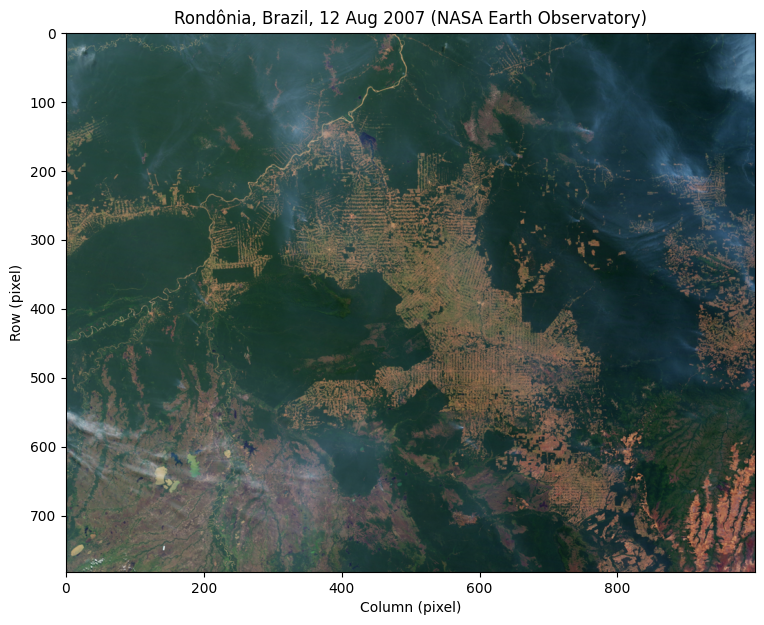

In [7]:
fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(rgb)
ax.set_title(image_title)
ax.set_xlabel('Column (pixel)')
ax.set_ylabel('Row (pixel)')
plt.show()

### Image coordinates vs map coordinates

The axes above are **pixel coordinates**: column numbers along x, and row numbers along y, counting **down** from the top-left corner. This JPEG has **no georeferencing**: nothing in the file says where on Earth each pixel is.

A **georeferenced** raster (e.g. a GeoTIFF, or an Earth Engine image) also stores a **coordinate reference system (CRS)** and a **transform** (the coordinates of the top-left corner and the pixel size). Then pixels can be placed on a map, combined with vector boundaries and measured in metres or hectares. We work with real georeferenced rasters in Weeks 7–8 (`rasterio`, `rioxarray`, Earth Engine). Section 8 shows the plotting side of this idea.

## 6.1 Single bands, colourmaps and colourbars

Indexing the third dimension selects one band. Again, the details come in Week 6:

(782, 1000) uint8


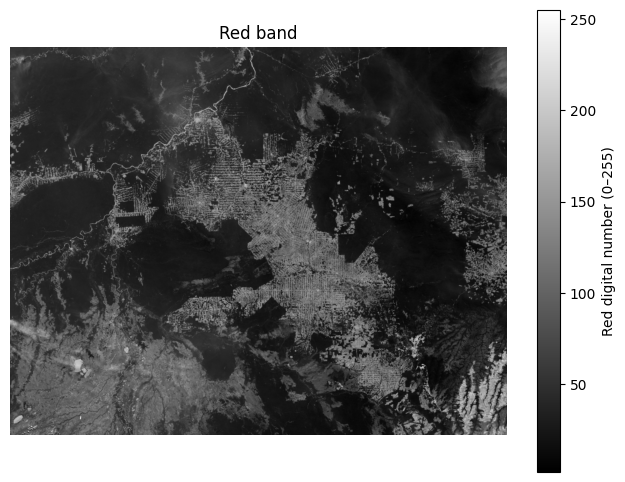

In [8]:
red   = rgb[:, :, 0]      # all rows, all columns, band 0
green = rgb[:, :, 1]
blue  = rgb[:, :, 2]
print(red.shape, red.dtype)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(red, cmap='gray')
fig.colorbar(im, ax=ax, label='Red digital number (0–255)')
ax.set_title('Red band')
ax.set_axis_off()
plt.show()

A single band has no colour of its own. A **colourmap** assigns colours to values, and a **colourbar** with units shows the key. Choose the colourmap by the **type of data**:

| Data | Colourmap type | Good choices | Example |
|---|---|---|---|
| ordered values from low to high | **sequential** | `viridis`, `cividis`, `magma`, `Greens`, `YlGn` | elevation, LAI, temperature, reflectance |
| values around a meaningful centre | **diverging** | `RdBu_r`, `BrBG`, `RdYlBu` | anomalies, change maps, NDVI difference |
| classes with no order | **qualitative** | `tab10`, `Set2`, or your own list | land cover |

- `viridis` and `cividis` are **perceptually uniform** and readable by people with colour-vision deficiency.
- Avoid `jet` and `rainbow`: they create false boundaries and are hard to read for about 1 in 12 men.
- For diverging data, make the centre of the colourmap match the meaningful value (often 0) with symmetric `vmin=-x, vmax=+x`.

A simple **visible-light greenness index** compares the green and red bands. It is *not* NDVI, which needs a near-infrared band that a JPEG doesn't have, but it behaves similarly for display:

$$\text{greenness} = \frac{G - R}{G + R}$$

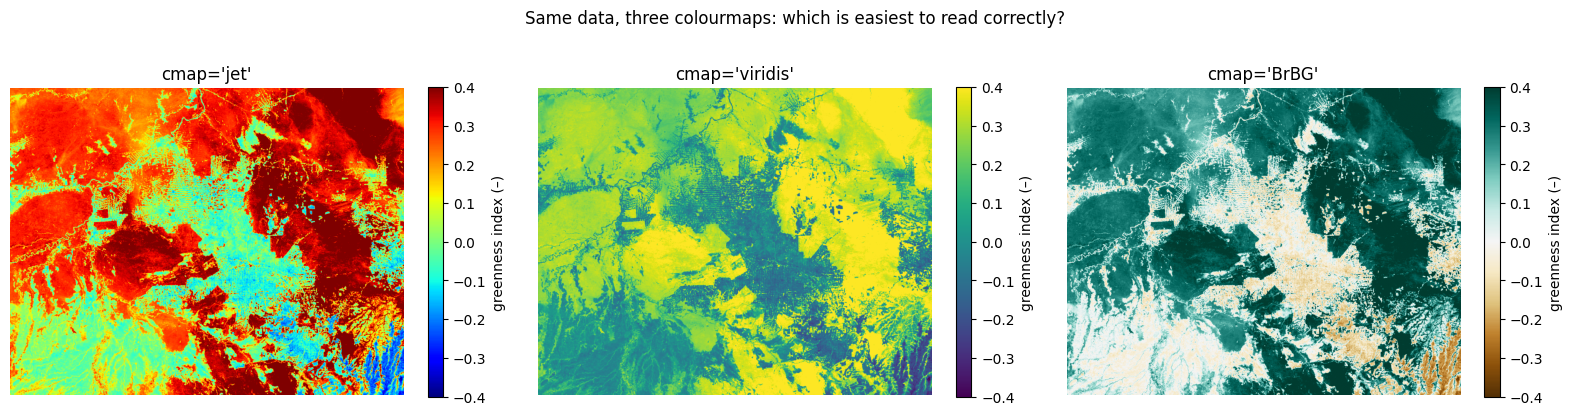

In [9]:
rgb_f = rgb.astype(float) / 255             # convert to floats from 0 to 1 (Week 6)
R, G = rgb_f[:, :, 0], rgb_f[:, :, 1]
greenness = (G - R) / (G + R + 1e-6)        # tiny number avoids division by zero
brightness = rgb_f.mean(axis=2)             # mean of the three bands

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, cmap in zip(axes, ['jet', 'viridis', 'BrBG']):
    im = ax.imshow(greenness, cmap=cmap, vmin=-0.4, vmax=0.4)
    fig.colorbar(im, ax=ax, label='greenness index (–)', shrink=0.8)
    ax.set_title(f"cmap='{cmap}'")
    ax.set_axis_off()
fig.suptitle('Same data, three colourmaps: which is easiest to read correctly?')
fig.tight_layout()
plt.show()

## 6.2 Contrast stretching

Satellite bands often use only a small part of their possible range, so they look dark or washed out. A **contrast stretch** maps a chosen range of values onto the full colour range. A robust choice is between the **2nd and 98th percentiles**, which ignores extreme pixels such as clouds and shadows. With `imshow`, set `vmin` and `vmax`:

2nd percentile: 13, 98th percentile: 139


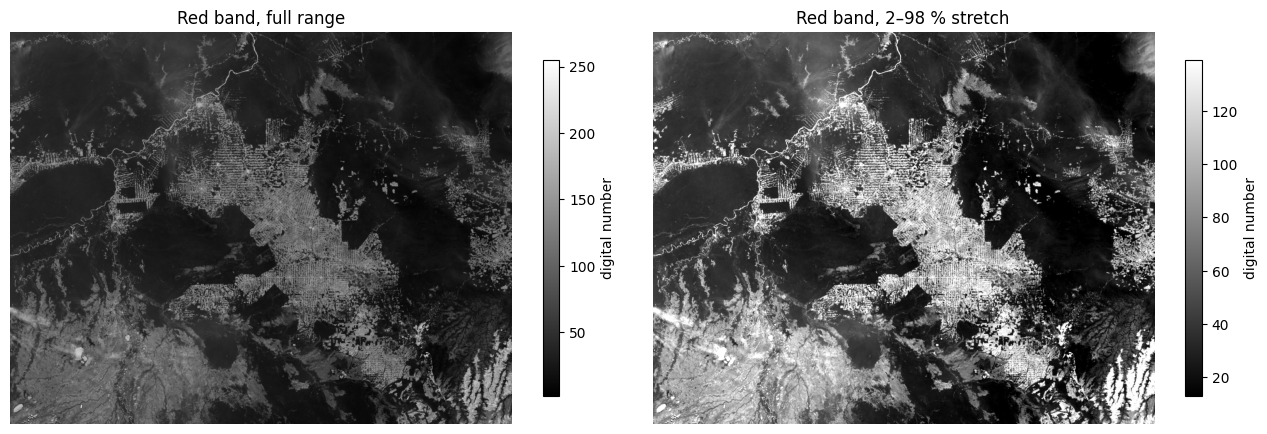

In [10]:
lo, hi = np.percentile(red, [2, 98])
print(f'2nd percentile: {lo:.0f}, 98th percentile: {hi:.0f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
im0 = axes[0].imshow(red, cmap='gray')
axes[0].set_title('Red band, full range')
im1 = axes[1].imshow(red, cmap='gray', vmin=lo, vmax=hi)
axes[1].set_title('Red band, 2–98 % stretch')
for ax, im in zip(axes, [im0, im1]):
    fig.colorbar(im, ax=ax, label='digital number', shrink=0.8)
    ax.set_axis_off()
fig.tight_layout()
plt.show()

#### Exercise 6: A four-panel image figure

Display four layers in a **2 × 2** grid:

1. the RGB image;
2. the red band, with `cmap='gray'` and a 2–98 % stretch;
3. the brightness layer, with a sequential colourmap of your choice;
4. the greenness index, with a **diverging** colourmap centred on 0.

Remove the tick marks (`ax.set_axis_off()`), give each panel a title, and add a colourbar **with a label** to the three single-band panels (not to the RGB image). Save the figure to `data/figures/rondonia_layers.png`.

In [ ]:
# Your code here

#### Exercise 7: A reusable layer-display function

Write a function `display_layers(layers, cmaps=None, ncols=2, figsize=(12, 9), out_path=None)` where:

- `layers` is a **dictionary** `{title: 2-D array}`;
- `cmaps` is an optional dictionary `{title: colourmap name}` (default `'viridis'` for any layer not listed);
- the number of **rows** is calculated from the number of layers and `ncols` (hint: `math.ceil` or `-(-n // ncols)`), and any unused panels are hidden with `ax.set_axis_off()`;
- every panel gets a title and a colourbar;
- the function **returns** the `fig`, and saves it if `out_path` is given.

Test it with 3 layers and then with 4 layers.

In [ ]:
# Your code here

---
# 7. Categorical rasters: land-cover-style maps

In a land-cover map, a pixel value such as `1`, `2` or `3` is a **class code**, not a quantity. A continuous colourbar would be misleading, because class 3 is not "more" than class 1. Use a **discrete colourmap** with one colour per class, and a **legend**.

Below we make a crude rule-based map from the image's brightness and greenness. It is **for display practice only**, not a valid classification; real classification comes later in the programme.

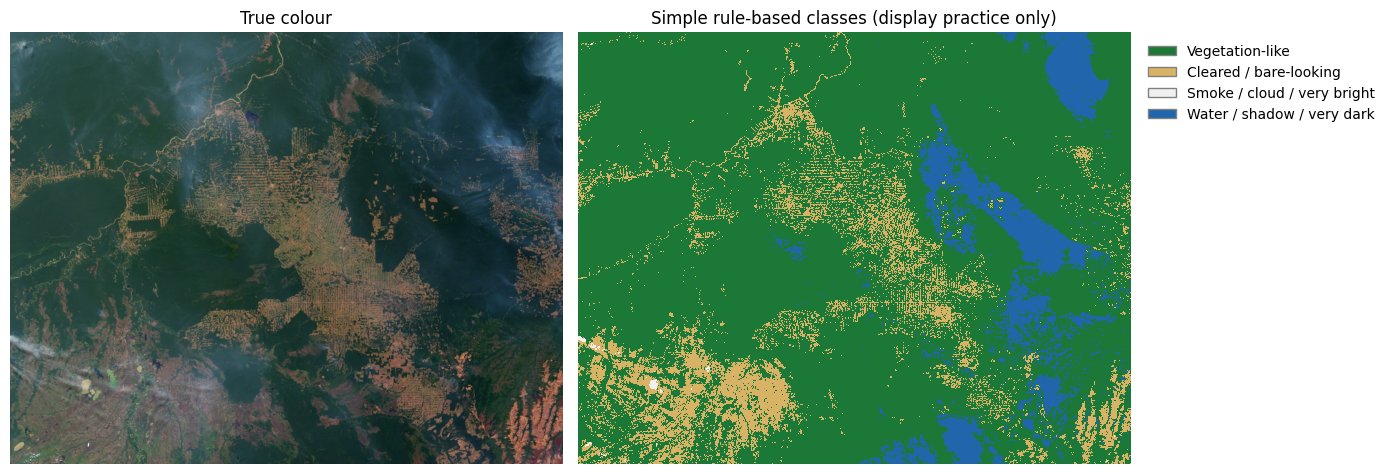

In [11]:
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

classes = {
    0: ('Vegetation-like', '#1b7837'),
    1: ('Cleared / bare-looking', '#d8b365'),
    2: ('Smoke / cloud / very bright', '#f0f0f0'),
    3: ('Water / shadow / very dark', '#2166ac'),
}

land_cover = np.zeros(greenness.shape, dtype=int)                    # start with class 0 everywhere
land_cover[(brightness > 0.38) & (greenness < 0.08)] = 1
land_cover[brightness > 0.62] = 2
land_cover[brightness < 0.14] = 3

cmap = mcolors.ListedColormap([colour for _, colour in classes.values()])
norm = mcolors.BoundaryNorm(np.arange(-0.5, len(classes)), cmap.N)   # one colour per integer

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(rgb)
axes[0].set_title('True colour')
axes[1].imshow(land_cover, cmap=cmap, norm=norm, interpolation='nearest')
axes[1].set_title('Simple rule-based classes (display practice only)')
handles = [mpatches.Patch(facecolor=c, edgecolor='grey', label=name) for name, c in classes.values()]
axes[1].legend(handles=handles, loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)
for ax in axes:
    ax.set_axis_off()
fig.tight_layout()
plt.show()

> `interpolation='nearest'` stops `imshow` from blending neighbouring pixels. Blending is wrong for class codes, because there is no class "1.5".

#### Exercise 8: How much of each class?

1. Count the pixels in each class with `np.unique(land_cover, return_counts=True)`.
2. Put the results in a DataFrame with columns `code`, `name`, `pixels` and `percent`.
3. Make a horizontal bar chart (`ax.barh`) of the **percentage** per class, using **the same colours** as the map.

(With a georeferenced raster, you would multiply the pixel counts by the pixel area to get hectares. For example, a 10 m Sentinel-2 pixel is 100 m².)

In [ ]:
# Your code here

---
# 8. From pixels to map coordinates (a preview)

`imshow(..., extent=[left, right, bottom, top])` places an array in **real coordinates**. With a georeferenced raster, the extent comes from the file's metadata. Here we use a small **synthetic** grid over the Greater London bounding box from Week 2, just to show how it works. We also mark the **Heathrow station**, whose coordinates come from the header of the Met Office file (51.479° N, 0.449° W).

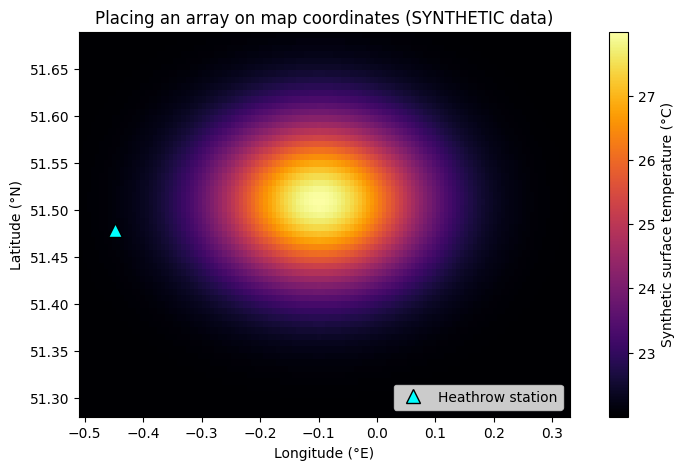

In [12]:
min_lon, min_lat, max_lon, max_lat = -0.51, 51.28, 0.33, 51.69      # Greater London bbox (approx.)

# SYNTHETIC field for illustration: warmer towards the centre, like an urban heat island
lon = np.linspace(min_lon, max_lon, 120)
lat = np.linspace(max_lat, min_lat, 60)               # top row = north
LON, LAT = np.meshgrid(lon, lat)
synthetic_lst = 22 + 6 * np.exp(-(((LON + 0.10) / 0.18) ** 2 + ((LAT - 51.51) / 0.09) ** 2))

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(synthetic_lst, extent=[min_lon, max_lon, min_lat, max_lat], cmap='inferno', origin='upper')
fig.colorbar(im, ax=ax, label='Synthetic surface temperature (°C)')
ax.plot(-0.449, 51.479, marker='^', color='cyan', markersize=10, markeredgecolor='black', ls='none',
        label='Heathrow station')
ax.set_xlabel('Longitude (°E)')
ax.set_ylabel('Latitude (°N)')
ax.set_title('Placing an array on map coordinates (SYNTHETIC data)')
ax.legend(loc='lower right')
ax.set_aspect(1 / np.cos(np.deg2rad(51.5)))           # so 1° lon and 1° lat look right at this latitude
plt.show()

Notes for the real thing (Weeks 7–8):

- Plotting longitude and latitude directly is fine for quick looks. For measuring area and distance, rasters are usually in a **projected** CRS such as British National Grid (EPSG:27700) or UTM (Sentinel-2 tile 30UXC is in UTM zone 30N, EPSG:32630), with x and y in **metres**.
- Packages such as `rioxarray` read the extent and CRS from the file, so you never type them by hand.
- **Interactive maps** (`folium`, `geemap`) are great for **exploring** data. For Part B **figures**, though, produce static maps with `matplotlib`.

---
# 9. Checklist for a good scientific figure

Before a figure goes into a report:

- [ ] **Title** (or caption) that says *what, where, when*.
- [ ] **Axis labels with units**, e.g. `Temperature (°C)`, `Rainfall (mm/month)`, or `NDVI (–)` for unitless values.
- [ ] **Legend** for every line, marker or class. **Colourbar with label and units** for every image.
- [ ] Suitable **colourmap**: sequential, diverging (centred) or qualitative. Readable by people with colour-vision deficiency, so no `jet`.
- [ ] Panels that should be compared share the **same axis limits** (`sharex`/`sharey`, or the same `vmin`/`vmax`).
- [ ] Text large enough to read at the size it will be printed.
- [ ] No artefacts mistaken for results (gaps, partial years, missing data).
- [ ] Saved with `savefig(..., dpi=300, bbox_inches='tight')`.
- [ ] A short **caption in your own words**: what it shows and what the reader should notice.

---
# 10. Formative exercise: a station climate summary figure

Write a function `station_climate_figure(df, station_name, out_path=None)` that takes a cleaned station DataFrame (as returned by `read_met_station()`) and produces **one figure with three panels**:

1. **annual mean Tmax and Tmin** (complete years only), each with a 10-year moving average;
2. the **monthly Tmax climatology** for 1961–1990 and 1991–2020;
3. a **histogram** of July Tmax for the two periods.

Requirements: titles, axis labels with units, legends, a figure title that includes `station_name`, saved at 300 dpi when `out_path` is given, and the function **returns** the figure. Include a docstring.

Call it for Heathrow and save the result as `data/figures/heathrow_summary.png`. Then, in a **markdown cell**, write a 3–4 sentence **caption in your own words** describing what the figure shows. (This is the kind of interpretation text that AI must not write for you in Part B.)

*Stretch:* if you have internet access, download another Met Office station (e.g. `.../stationdata/oxforddata.txt`) and run the same function, which needs no code changes.

In [ ]:
# Your code here

*Your caption here (in your own words):*

---
# Summary

| Topic | Key points |
|---|---|
| Figure anatomy | `fig, ax = plt.subplots(figsize=...)`; `ax.plot`, `ax.set_title/xlabel/ylabel`, `ax.legend()`; always give units |
| Panels | `plt.subplots(r, c, sharex=, sharey=)`, `axes.flatten()` in a loop, `fig.suptitle`, `fig.tight_layout()` |
| Plot types | `plot` (time), `scatter` (relationships, `c=` for a 3rd variable), `bar`/`barh` (categories), `hist` (distributions), `errorbar`/`fill_between` (spread) |
| Time series | dates on the x-axis, `.rolling(n, center=True).mean()`, `axhline`, `axvspan`, `text` |
| Saving | `fig.savefig(path, dpi=300, bbox_inches='tight')` before `plt.show()`; PNG or PDF/SVG |
| Images | arrays of shape (rows, cols) or (rows, cols, bands); `imshow`; pixel vs map coordinates |
| Colour | sequential / diverging (centred) / qualitative; `viridis`, `cividis`, `BrBG`; avoid `jet`; colourbar with label |
| Stretch | `vmin`/`vmax` from `np.percentile(band, [2, 98])` |
| Categorical | `ListedColormap` + `BoundaryNorm`, `interpolation='nearest'`, legend patches, `np.unique(..., return_counts=True)` |
| Map coordinates | `imshow(..., extent=[left, right, bottom, top])`; real CRS and transform come from the file (Weeks 7–8) |

**Next week (Week 6):** **NumPy**: the array operations you previewed today (indexing bands, `astype`, `mean(axis=...)`, boolean masks, percentiles), which are the basis of all raster processing.

---
# Resources

## Cheat sheets and references

| Resource | What it covers |
|---|---|
| [Matplotlib cheat sheets and handouts](https://matplotlib.org/cheatsheets/) | Official cheat sheets (beginner, intermediate and the full sheet with every plot type and colourmap). **Print the beginner one.** |
| [Matplotlib Quick start guide](https://matplotlib.org/stable/users/explain/quick_start.html) | The Figure/Axes model and the object-oriented style used here |
| [Choosing colormaps in Matplotlib](https://matplotlib.org/stable/users/explain/colors/colormaps.html) | Sequential, diverging and qualitative colourmaps, and why perceptual uniformity matters |
| [ColorBrewer](https://colorbrewer2.org/) | Colour schemes for maps, with colour-blind-safe and print-friendly filters |
| [From Data to Viz](https://www.data-to-viz.com/) | A decision tree for choosing the right chart type for your data |
| [Python Graph Gallery](https://python-graph-gallery.com/) | Hundreds of example plots with code, to adapt |
| [pandas cheat sheet](https://pandas.pydata.org/Pandas_Cheat_Sheet.pdf) | Still useful: preparing the data is most of the work |

## Practise

There are fewer auto-graded sites for plotting than for basic Python, because a computer can't easily judge whether a figure is good. These are the best options:

| Site | Good for | How it checks |
|---|---|---|
| [Kaggle Learn: Data Visualization](https://www.kaggle.com/learn/data-visualization) | Short hands-on lessons (using `seaborn`, which is built on matplotlib): line, bar, heatmap, scatter and distribution plots | Each exercise has a `check()` step |
| [W3Schools Matplotlib tutorial](https://www.w3schools.com/python/matplotlib_intro.asp) | Very short examples of each plot type with a try-it-yourself editor | You compare your plot with the example |
| [Software Carpentry: Plotting and Programming in Python](https://swcarpentry.github.io/python-novice-gapminder/) | The plotting episode, with exercises and solutions | Solutions provided |
| **Recreate-a-figure challenge** | Pick a figure from a paper in your field and recreate its style with your own data | Compare side by side: the best way to learn |

## Earth Observation display

- [Earth Data Science textbook (Earth Lab)](https://www.earthdatascience.org/courses/intro-to-earth-data-science/): includes plotting with matplotlib and introductions to raster data in Python.
- Colour-vision deficiency check: search for a "colour blindness simulator" and upload a saved PNG to see how your figure looks to colour-blind readers.